In [1]:
# ============================================================
# STAGE 4 - CELL 1: Import Libraries and Load Sequences
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib
import warnings
warnings.filterwarnings('ignore')

# TensorFlow and Keras — for building the neural network
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv1D, BatchNormalization, Dropout,
    Bidirectional, LSTM, Dense, Flatten
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
)

# Scikit-learn metrics for evaluation
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# Set random seeds for reproducibility
# This ensures you get the same results every time you run
np.random.seed(42)
tf.random.set_seed(42)

# Plot styling
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size']      = 11
plt.rcParams['axes.grid']      = True
plt.rcParams['grid.alpha']     = 0.3
sns.set_theme(style="whitegrid")

# ── Paths ─────────────────────────────────────────────────────
PROJECT_ROOT  = "C:/Users/USER/Desktop/Solar_Energy_Forecasting_Project"
RESULTS_DIR  = os.path.join(PROJECT_ROOT, "results")
MODELS_DIR   = os.path.join(PROJECT_ROOT, "models")
PLOTS_DIR    = os.path.join(PROJECT_ROOT, "plots")
SEQ_DIR      = os.path.join(RESULTS_DIR, "sequences")

# ── Load all sequences saved in Stage 3 ───────────────────────
print("Loading sequences...")

# Kano
X_train_kano = np.load(os.path.join(SEQ_DIR,'X_train_kano.npy'))
y_train_kano = np.load(os.path.join(SEQ_DIR,'y_train_kano.npy'))
X_val_kano   = np.load(os.path.join(SEQ_DIR,'X_val_kano.npy'))
y_val_kano   = np.load(os.path.join(SEQ_DIR,'y_val_kano.npy'))
X_test_kano  = np.load(os.path.join(SEQ_DIR,'X_test_kano.npy'))
y_test_kano  = np.load(os.path.join(SEQ_DIR,'y_test_kano.npy'))

# Maiduguri
X_train_maid = np.load(os.path.join(SEQ_DIR,'X_train_maid.npy'))
y_train_maid = np.load(os.path.join(SEQ_DIR,'y_train_maid.npy'))
X_val_maid   = np.load(os.path.join(SEQ_DIR,'X_val_maid.npy'))
y_val_maid   = np.load(os.path.join(SEQ_DIR,'y_val_maid.npy'))
X_test_maid  = np.load(os.path.join(SEQ_DIR,'X_test_maid.npy'))
y_test_maid  = np.load(os.path.join(SEQ_DIR,'y_test_maid.npy'))

# Abuja
X_train_abuja = np.load(os.path.join(SEQ_DIR,'X_train_abuja.npy'))
y_train_abuja = np.load(os.path.join(SEQ_DIR,'y_train_abuja.npy'))
X_val_abuja   = np.load(os.path.join(SEQ_DIR,'X_val_abuja.npy'))
y_val_abuja   = np.load(os.path.join(SEQ_DIR,'y_val_abuja.npy'))
X_test_abuja  = np.load(os.path.join(SEQ_DIR,'X_test_abuja.npy'))
y_test_abuja  = np.load(os.path.join(SEQ_DIR,'y_test_abuja.npy'))

# Load scalers
tgt_scaler_kano  = joblib.load(
    os.path.join(MODELS_DIR,'tgt_scaler_kano.pkl'))
tgt_scaler_maid  = joblib.load(
    os.path.join(MODELS_DIR,'tgt_scaler_maid.pkl'))
tgt_scaler_abuja = joblib.load(
    os.path.join(MODELS_DIR,'tgt_scaler_abuja.pkl'))

print("="*55)
print("ALL SEQUENCES LOADED SUCCESSFULLY")
print("="*55)
print(f"\nKano    Train: {X_train_kano.shape}")
print(f"Kano    Val  : {X_val_kano.shape}")
print(f"Kano    Test : {X_test_kano.shape}")
print(f"\nMaiduguri Train: {X_train_maid.shape}")
print(f"Abuja     Train: {X_train_abuja.shape}")

# Model input dimensions — derived from data shape
WINDOW_SIZE  = X_train_kano.shape[1]   # 24
N_FEATURES   = X_train_kano.shape[2]   # 17
print(f"\nWindow size : {WINDOW_SIZE} timesteps")
print(f"N features  : {N_FEATURES} features per timestep")

Loading sequences...
ALL SEQUENCES LOADED SUCCESSFULLY

Kano    Train: (52560, 24, 17)
Kano    Val  : (8736, 24, 17)
Kano    Test : (8736, 24, 17)

Maiduguri Train: (52560, 24, 17)
Abuja     Train: (52560, 24, 17)

Window size : 24 timesteps
N features  : 17 features per timestep


In [2]:
# ============================================================
# STAGE 4 - CELL 2: Build CNN-biLSTM Architecture
# ============================================================

def build_cnn_bilstm(window_size, n_features,
                     filters=64, kernel_size=5,
                     lstm_units=64, dropout_rate=0.10,
                     learning_rate=0.001):
    """
    Builds the hybrid CNN-biLSTM model for solar PV forecasting.

    Architecture:
    Input → CNN Block 1 → CNN Block 2 → biLSTM → Dense → Output

    Parameters:
        window_size   : number of timesteps in each sequence (24)
        n_features    : number of input features per timestep (17)
        filters       : number of CNN filters (64)
        kernel_size   : CNN kernel size — looks at 5 timesteps at once
        lstm_units    : number of biLSTM units per direction (64)
        dropout_rate  : fraction of neurons dropped during training (0.10)
        learning_rate : step size for gradient descent (0.001)

    Returns:
        model : compiled Keras model ready for training
    """

    # ── Input Layer ───────────────────────────────────────────
    # Defines the shape of one input sequence
    # Shape: (window_size, n_features) = (24, 17)
    inputs = Input(shape=(window_size, n_features),
                   name='Input_Layer')

    # ── CNN Block 1 ───────────────────────────────────────────
    # Conv1D slides 64 filters of size 5 across the time dimension
    # Each filter learns to detect a specific local pattern
    # e.g. morning irradiance ramp-up, sudden cloud-induced drop
    # padding='same' keeps the sequence length unchanged
    x = Conv1D(filters=filters,
               kernel_size=kernel_size,
               activation='relu',
               padding='same',
               name='Conv1D_Block1')(inputs)

    # BatchNormalization stabilises training by normalising
    # the outputs of each layer before passing to the next
    # This allows higher learning rates and faster convergence
    x = BatchNormalization(name='BatchNorm_1')(x)

    # Dropout randomly sets 10% of neurons to zero during training
    # This prevents the model from memorising training data
    # and forces it to learn more robust, generalisable patterns
    x = Dropout(dropout_rate, name='Dropout_1')(x)

    # ── CNN Block 2 ───────────────────────────────────────────
    # Second convolutional block learns higher-level patterns
    # by combining the local patterns detected in Block 1
    # e.g. Block 1 might detect "sharp irradiance rise"
    # Block 2 combines this with temperature pattern to detect
    # "high-irradiance high-temperature harmattan morning"
    x = Conv1D(filters=filters,
               kernel_size=kernel_size,
               activation='relu',
               padding='same',
               name='Conv1D_Block2')(x)

    x = BatchNormalization(name='BatchNorm_2')(x)
    x = Dropout(dropout_rate, name='Dropout_2')(x)

    # ── Bidirectional LSTM Layer ──────────────────────────────
    # The biLSTM reads the CNN output sequence in BOTH directions
    # Forward pass : processes hours 1→24 (past to present)
    # Backward pass: processes hours 24→1 (present to past)
    # Both passes are concatenated giving 128D output per timestep
    # return_sequences=False means only the final timestep's
    # hidden state is returned — a single 128D vector that
    # summarises the entire 24-hour window
    x = Bidirectional(
        LSTM(lstm_units,
             return_sequences=False,
             dropout=dropout_rate),
        name='BiLSTM_Layer')(x)

    # Additional dropout after biLSTM
    x = Dropout(dropout_rate, name='Dropout_3')(x)

    # ── Output Layer ──────────────────────────────────────────
    # Single neuron with linear activation
    # Outputs one number — the predicted normalised PV power
    # Linear activation means no squashing — output can be
    # any real number (appropriate for regression problems)
    outputs = Dense(1, activation='linear',
                    name='Output_Layer')(x)

    # ── Compile the Model ─────────────────────────────────────
    model = Model(inputs=inputs, outputs=outputs,
                  name='CNN_biLSTM_Solar_Forecaster')

    # Adam optimiser — adaptive learning rate optimisation
    # It adjusts the learning rate automatically for each
    # parameter based on recent gradient history
    # Much faster and more reliable than standard SGD
    optimizer = Adam(learning_rate=learning_rate)

    # MSE loss function — mean squared error
    # Appropriate for regression (continuous value prediction)
    # Penalises large errors more than small ones (quadratic)
    model.compile(
        optimizer=optimizer,
        loss='mse',
        metrics=['mae']   # Also track MAE during training
    )

    return model


# Build the model
model = build_cnn_bilstm(
    window_size   = WINDOW_SIZE,    # 24
    n_features    = N_FEATURES,     # 17
    filters       = 64,
    kernel_size   = 5,
    lstm_units    = 64,
    dropout_rate  = 0.10,
    learning_rate = 0.001
)

# Print model summary — shows every layer and parameter count
print("="*55)
print("CNN-biLSTM MODEL ARCHITECTURE")
print("="*55)
model.summary()

CNN-biLSTM MODEL ARCHITECTURE


Model: "CNN_biLSTM_Solar_Forecaster"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ Input_Layer (InputLayer)             │ (None, 24, 17)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Conv1D_Block1 (Conv1D)               │ (None, 24, 64)              │           5,504 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ BatchNorm_1 (BatchNormalization)     │ (None, 24, 64)              │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Dropout_1 (Dropout)                  │ (None, 24, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Conv1D_Block2 (Conv1D)               │ (None, 24, 64)              │          20,544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ BatchNorm_2 (BatchNormalization)     │ (None, 24, 64)              │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Dropout_2 (Dropout)                  │ (None, 24, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ BiLSTM_Layer (Bidirectional)         │ (None, 128)                 │          66,048 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Dropout_3 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Output_Layer (Dense)                 │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 92,737 (362.25 KB)

 Trainable params: 92,481 (361.25 KB)

 Non-trainable params: 256 (1.00 KB)

In [3]:
# ============================================================
# STAGE 4 - CELL 3: Define Training Callbacks
# ============================================================

# Callbacks are functions that run automatically at the end
# of each training epoch. They monitor training progress
# and take actions to improve or control training.

def get_callbacks(city_name):
    """
    Creates three callbacks for model training:
    1. EarlyStopping   — stops training when improvement plateaus
    2. ReduceLROnPlateau — reduces learning rate when stuck
    3. ModelCheckpoint  — saves the best model automatically
    """

    # ── Callback 1: Early Stopping ────────────────────────────
    # Monitors validation loss after every epoch
    # If val_loss does not improve for 15 consecutive epochs,
    # training stops automatically — preventing overfitting
    # restore_best_weights=True reloads the best weights found
    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=15,           # Wait 15 epochs before stopping
        restore_best_weights=True,
        verbose=1
    )

    # ── Callback 2: Reduce Learning Rate on Plateau ───────────
    # If val_loss does not improve for 7 epochs,
    # learning rate is multiplied by 0.5 (halved)
    # This helps the model escape flat regions of the loss landscape
    # min_lr sets a floor so learning rate never becomes zero
    reduce_lr = ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,           # Halve the learning rate
        patience=7,           # Wait 7 epochs before reducing
        min_lr=1e-6,          # Minimum learning rate
        verbose=1
    )

    # ── Callback 3: Model Checkpoint ─────────────────────────
    # Saves the model weights to disk every time val_loss
    # improves — so you always have the best version saved
    # even if training continues and then deteriorates
    checkpoint_path = os.path.join(
        MODELS_DIR, f'best_cnn_bilstm_{city_name}.keras')

    checkpoint = ModelCheckpoint(
        filepath=checkpoint_path,
        monitor='val_loss',
        save_best_only=True,   # Only save when val_loss improves
        verbose=1
    )

    return [early_stop, reduce_lr, checkpoint], checkpoint_path


print("="*55)
print("CALLBACKS DEFINED")
print("="*55)
print("\nEarlyStopping   : stops if no val_loss improvement for 15 epochs")
print("ReduceLROnPlateau: halves lr if no improvement for 7 epochs")
print("ModelCheckpoint : saves best model weights automatically")

CALLBACKS DEFINED

EarlyStopping   : stops if no val_loss improvement for 15 epochs
ReduceLROnPlateau: halves lr if no improvement for 7 epochs
ModelCheckpoint : saves best model weights automatically


In [4]:
# ============================================================
# STAGE 4 - CELL 4: Train CNN-biLSTM on Kano Data
# ============================================================

print("="*55)
print("TRAINING CNN-biLSTM — KANO")
print("="*55)
print(f"Training sequences  : {X_train_kano.shape[0]:,}")
print(f"Validation sequences: {X_val_kano.shape[0]:,}")
print(f"Input shape         : {X_train_kano.shape[1:]}")
print(f"Max epochs          : 120")
print(f"Batch size          : 64")
print(f"\nTraining started...\n")

# Build a fresh model for Kano
model_kano = build_cnn_bilstm(WINDOW_SIZE, N_FEATURES)

# Get callbacks for Kano
callbacks_kano, ckpt_kano = get_callbacks('kano')

# Train the model
history_kano = model_kano.fit(
    X_train_kano, y_train_kano,      # Training data

    validation_data=(
        X_val_kano, y_val_kano),     # Validation data

    epochs=120,                       # Maximum training epochs
    batch_size=64,                    # Sequences per gradient update

    callbacks=callbacks_kano,         # Early stop, LR reduce, save

    verbose=1,                        # Print progress each epoch
    shuffle=False                     # Never shuffle time-series data
)

print("\n" + "="*55)
print("KANO TRAINING COMPLETE")
print("="*55)
print(f"Total epochs trained : {len(history_kano.history['loss'])}")
print(f"Best val_loss        : "
      f"{min(history_kano.history['val_loss']):.6f}")
print(f"Best val_mae         : "
      f"{min(history_kano.history['val_mae']):.6f}")
print(f"Model saved to       : {ckpt_kano}")

TRAINING CNN-biLSTM — KANO
Training sequences  : 52,560
Validation sequences: 8,736
Input shape         : (24, 17)
Max epochs          : 120
Batch size          : 64

Training started...

Epoch 1/120
822/822 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - loss: 0.0074 - mae: 0.0581
Epoch 1: val_loss improved from None to 0.00678, saving model to C:/Users/Mahir/Desktop/Solar_Energy_Forecasting_Project\models\best_cnn_bilstm_kano.keras

Epoch 1: finished saving model to C:/Users/Mahir/Desktop/Solar_Energy_Forecasting_Project\models\best_cnn_bilstm_kano.keras
822/822 ━━━━━━━━━━━━━━━━━━━━ 68s 55ms/step - loss: 0.0074 - mae: 0.0581 - val_loss: 0.0068 - val_mae: 0.0549 - learning_rate: 0.0010
Epoch 2/120
821/822 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - loss: 0.0022 - mae: 0.0307
Epoch 2: val_loss improved from 0.00678 to 0.00459, saving model to C:/Users/Mahir/Desktop/Solar_Energy_Forecasting_Project\models\best_cnn_bilstm_kano.keras

Epoch 2: finished saving model to C:/Users/Mahir/Desktop/Solar_Energy_Fore

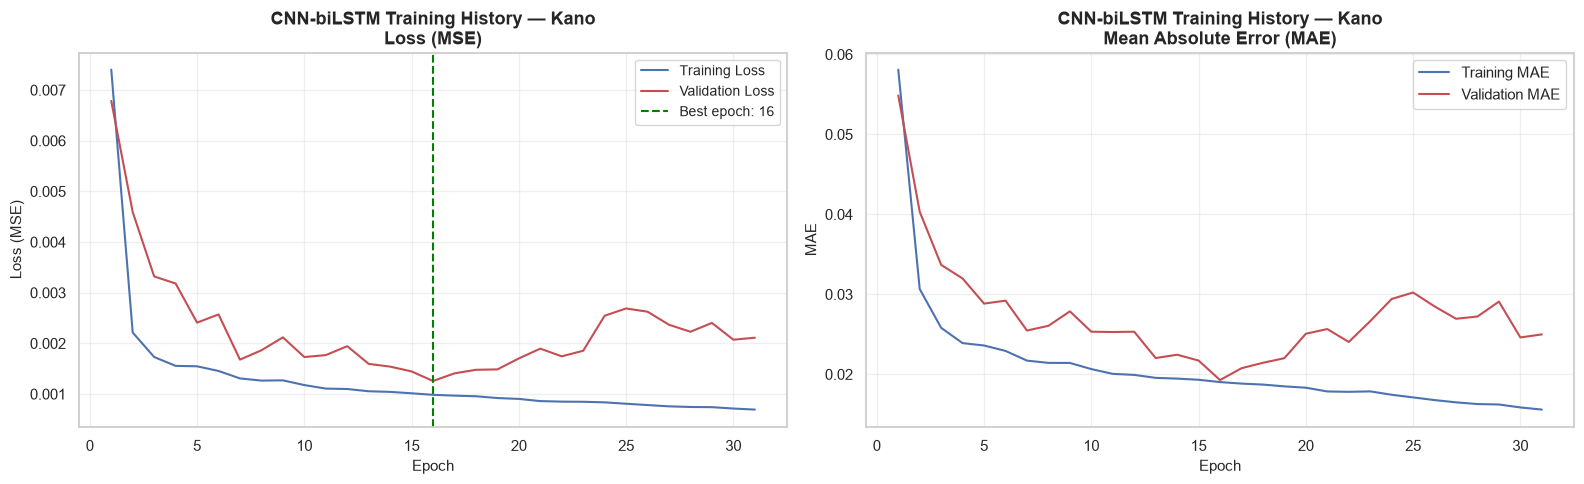

✅ Plot saved: C:/Users/Mahir/Desktop/Solar_Energy_Forecasting_Project\plots\Training_history_kano.png


In [5]:
# ============================================================
# STAGE 4 - CELL 5: Plot Kano Training History
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

epochs = range(1, len(history_kano.history['loss']) + 1)

# ── Plot 1: Training vs Validation Loss ───────────────────────
axes[0].plot(epochs,
             history_kano.history['loss'],
             'b-', linewidth=1.5,
             label='Training Loss')
axes[0].plot(epochs,
             history_kano.history['val_loss'],
             'r-', linewidth=1.5,
             label='Validation Loss')
axes[0].set_title('CNN-biLSTM Training History — Kano\n'
                   'Loss (MSE)',
                   fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=11)
axes[0].set_ylabel('Loss (MSE)', fontsize=11)
axes[0].legend(fontsize=11)

# Mark the best epoch (minimum validation loss)
best_epoch = np.argmin(history_kano.history['val_loss']) + 1
best_val   = min(history_kano.history['val_loss'])
axes[0].axvline(x=best_epoch, color='green',
                linestyle='--', linewidth=1.5,
                label=f'Best epoch: {best_epoch}')
axes[0].legend(fontsize=10)

# ── Plot 2: Training vs Validation MAE ────────────────────────
axes[1].plot(epochs,
             history_kano.history['mae'],
             'b-', linewidth=1.5,
             label='Training MAE')
axes[1].plot(epochs,
             history_kano.history['val_mae'],
             'r-', linewidth=1.5,
             label='Validation MAE')
axes[1].set_title('CNN-biLSTM Training History — Kano\n'
                   'Mean Absolute Error (MAE)',
                   fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=11)
axes[1].set_ylabel('MAE', fontsize=11)
axes[1].legend(fontsize=11)

plt.tight_layout()
save_path = os.path.join(PLOTS_DIR,
                          'Training_history_kano.png')
plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Plot saved: {save_path}")

In [6]:
# ============================================================
# STAGE 4 - CELL 6: Train on Maiduguri and Abuja
# ============================================================

# ── Maiduguri ─────────────────────────────────────────────────
print("="*55)
print("TRAINING CNN-biLSTM — MAIDUGURI")
print("="*55)

model_maid          = build_cnn_bilstm(WINDOW_SIZE, N_FEATURES)
callbacks_maid, ckpt_maid = get_callbacks('maiduguri')

history_maid = model_maid.fit(
    X_train_maid, y_train_maid,
    validation_data=(X_val_maid, y_val_maid),
    epochs=120,
    batch_size=64,
    callbacks=callbacks_maid,
    verbose=1,
    shuffle=False
)

print(f"\n✅ Maiduguri training complete")
print(f"   Epochs trained: {len(history_maid.history['loss'])}")
print(f"   Best val_loss : "
      f"{min(history_maid.history['val_loss']):.6f}")

# ── Abuja ─────────────────────────────────────────────────────
print("\n" + "="*55)
print("TRAINING CNN-biLSTM — ABUJA")
print("="*55)

model_abuja          = build_cnn_bilstm(WINDOW_SIZE, N_FEATURES)
callbacks_abuja, ckpt_abuja = get_callbacks('abuja')

history_abuja = model_abuja.fit(
    X_train_abuja, y_train_abuja,
    validation_data=(X_val_abuja, y_val_abuja),
    epochs=120,
    batch_size=64,
    callbacks=callbacks_abuja,
    verbose=1,
    shuffle=False
)

print(f"\n✅ Abuja training complete")
print(f"   Epochs trained: {len(history_abuja.history['loss'])}")
print(f"   Best val_loss : "
      f"{min(history_abuja.history['val_loss']):.6f}")

print("\n" + "="*55)
print("ALL THREE CITIES TRAINED SUCCESSFULLY")
print("="*55)

TRAINING CNN-biLSTM — MAIDUGURI
Epoch 1/120
822/822 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - loss: 0.0076 - mae: 0.0569
Epoch 1: val_loss improved from None to 0.00577, saving model to C:/Users/Mahir/Desktop/Solar_Energy_Forecasting_Project\models\best_cnn_bilstm_maiduguri.keras

Epoch 1: finished saving model to C:/Users/Mahir/Desktop/Solar_Energy_Forecasting_Project\models\best_cnn_bilstm_maiduguri.keras
822/822 ━━━━━━━━━━━━━━━━━━━━ 55s 55ms/step - loss: 0.0076 - mae: 0.0569 - val_loss: 0.0058 - val_mae: 0.0512 - learning_rate: 0.0010
Epoch 2/120
822/822 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - loss: 0.0023 - mae: 0.0298
Epoch 2: val_loss did not improve from 0.00577
822/822 ━━━━━━━━━━━━━━━━━━━━ 43s 53ms/step - loss: 0.0023 - mae: 0.0298 - val_loss: 0.0101 - val_mae: 0.0600 - learning_rate: 0.0010
Epoch 3/120
822/822 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - loss: 0.0020 - mae: 0.0265
Epoch 3: val_loss did not improve from 0.00577
822/822 ━━━━━━━━━━━━━━━━━━━━ 43s 52ms/step - loss: 0.0020 - mae: 0.02

In [7]:
# ============================================================
# STAGE 4 - CELL 7: Generate Predictions on Test Data (2023)
# ============================================================

# Load the best saved model weights
# (ModelCheckpoint saved the best version during training)
from tensorflow.keras.models import load_model

model_kano  = load_model(os.path.join(
    MODELS_DIR, 'best_cnn_bilstm_kano.keras'))
model_maid  = load_model(os.path.join(
    MODELS_DIR, 'best_cnn_bilstm_maiduguri.keras'))
model_abuja = load_model(os.path.join(
    MODELS_DIR, 'best_cnn_bilstm_abuja.keras'))

print("Best models loaded successfully\n")

def get_predictions(model, X_test, y_test, target_scaler):
    """
    Generates predictions on test data and converts them
    back from normalised scale (0-1) to real kW values.

    Returns both normalised and real-scale arrays for
    metric calculation and plotting.
    """

    # Generate normalised predictions
    y_pred_norm = model.predict(
        X_test, verbose=0).flatten()

    # Convert predictions from 0-1 scale back to real kW
    # using the inverse of the MinMax transformation
    y_pred_kw = target_scaler.inverse_transform(
        y_pred_norm.reshape(-1, 1)).flatten()

    # Convert actual test values back to real kW too
    y_true_kw = target_scaler.inverse_transform(
        y_test.reshape(-1, 1)).flatten()

    return y_pred_norm, y_pred_kw, y_true_kw


# Generate predictions for all three cities
(y_pred_norm_kano,
 y_pred_kw_kano,
 y_true_kw_kano)  = get_predictions(
    model_kano,  X_test_kano,
    y_test_kano, tgt_scaler_kano)

(y_pred_norm_maid,
 y_pred_kw_maid,
 y_true_kw_maid)  = get_predictions(
    model_maid,  X_test_maid,
    y_test_maid, tgt_scaler_maid)

(y_pred_norm_abuja,
 y_pred_kw_abuja,
 y_true_kw_abuja) = get_predictions(
    model_abuja,  X_test_abuja,
    y_test_abuja, tgt_scaler_abuja)

print("="*55)
print("PREDICTIONS GENERATED — TEST SET (2023)")
print("="*55)
print(f"\nKano    predictions: {len(y_pred_kw_kano):,} hours")
print(f"Maiduguri           : {len(y_pred_kw_maid):,} hours")
print(f"Abuja               : {len(y_pred_kw_abuja):,} hours")
print(f"\nKano predicted range: "
      f"{y_pred_kw_kano.min():.1f} to "
      f"{y_pred_kw_kano.max():.1f} kW")
print(f"Kano actual range   : "
      f"{y_true_kw_kano.min():.1f} to "
      f"{y_true_kw_kano.max():.1f} kW")

Best models loaded successfully

PREDICTIONS GENERATED — TEST SET (2023)

Kano    predictions: 8,736 hours
Maiduguri           : 8,736 hours
Abuja               : 8,736 hours

Kano predicted range: -51.2 to 719.4 kW
Kano actual range   : 0.0 to 834.1 kW


In [8]:
# ============================================================
# STAGE 4 - CELL 8: Calculate Performance Metrics
# ============================================================

def compute_metrics(y_true, y_pred, city_name):
    """
    Computes all four evaluation metrics:
    RMSE  — Root Mean Square Error (kW)
    MAE   — Mean Absolute Error (kW)
    R²    — Coefficient of Determination
    MAPE  — Mean Absolute Percentage Error (%)

    Evaluates on DAYTIME hours only (where actual power > 0)
    because including nighttime zeros would artificially
    inflate the accuracy metrics.
    """

    # Filter to daytime only (actual power > 0)
    mask   = y_true > 0
    y_true_day = y_true[mask]
    y_pred_day = y_pred[mask]

    # RMSE — penalises large errors most heavily
    rmse = np.sqrt(mean_squared_error(y_true_day, y_pred_day))

    # MAE — average magnitude of errors
    mae  = mean_absolute_error(y_true_day, y_pred_day)

    # R² — proportion of variance explained by model
    r2   = r2_score(y_true_day, y_pred_day)

    # MAPE — error as percentage of actual value
    # Add small epsilon to avoid division by zero
    mape = np.mean(np.abs(
        (y_true_day - y_pred_day) /
        (y_true_day + 1e-8))) * 100

    # nRMSE — RMSE normalised by mean actual power
    # Allows comparison across cities with different scales
    nrmse = (rmse / y_true_day.mean()) * 100

    print(f"\n{'─'*40}")
    print(f"METRICS — {city_name.upper()} (Test 2023)")
    print(f"{'─'*40}")
    print(f"  RMSE  : {rmse:.4f} kW")
    print(f"  MAE   : {mae:.4f} kW")
    print(f"  R²    : {r2:.6f}")
    print(f"  MAPE  : {mape:.2f} %")
    print(f"  nRMSE : {nrmse:.2f} %")

    return {'city': city_name, 'RMSE': rmse, 'MAE': mae,
            'R2': r2, 'MAPE': mape, 'nRMSE': nrmse}


print("="*55)
print("CNN-biLSTM PERFORMANCE — TEST SET 2023")
print("="*55)

metrics_kano  = compute_metrics(
    y_true_kw_kano,  y_pred_kw_kano,  'Kano')
metrics_maid  = compute_metrics(
    y_true_kw_maid,  y_pred_kw_maid,  'Maiduguri')
metrics_abuja = compute_metrics(
    y_true_kw_abuja, y_pred_kw_abuja, 'Abuja')

# Save metrics to DataFrame for easy comparison later
metrics_df = pd.DataFrame([
    metrics_kano, metrics_maid, metrics_abuja])
metrics_df.to_csv(
    os.path.join(RESULTS_DIR,
                 'cnn_bilstm_metrics.csv'),
    index=False)

print(f"\n{'='*55}")
print("METRICS SUMMARY TABLE")
print(f"{'='*55}")
print(metrics_df.to_string(index=False))
print(f"\n✅ Metrics saved to cnn_bilstm_metrics.csv")

CNN-biLSTM PERFORMANCE — TEST SET 2023

────────────────────────────────────────
METRICS — KANO (Test 2023)
────────────────────────────────────────
  RMSE  : 37.1633 kW
  MAE   : 25.9985 kW
  R²    : 0.975220
  MAPE  : 18.79 %
  nRMSE : 10.16 %

────────────────────────────────────────
METRICS — MAIDUGURI (Test 2023)
────────────────────────────────────────
  RMSE  : 54.1675 kW
  MAE   : 41.4907 kW
  R²    : 0.946654
  MAPE  : 46.29 %
  nRMSE : 14.98 %

────────────────────────────────────────
METRICS — ABUJA (Test 2023)
────────────────────────────────────────
  RMSE  : 47.2580 kW
  MAE   : 35.6903 kW
  R²    : 0.955765
  MAPE  : 31.08 %
  nRMSE : 14.13 %

METRICS SUMMARY TABLE
     city      RMSE       MAE       R2      MAPE     nRMSE
     Kano 37.163311 25.998485 0.975220 18.787127 10.162105
Maiduguri 54.167514 41.490738 0.946654 46.292680 14.979989
    Abuja 47.257965 35.690298 0.955765 31.075835 14.134259

✅ Metrics saved to cnn_bilstm_metrics.csv


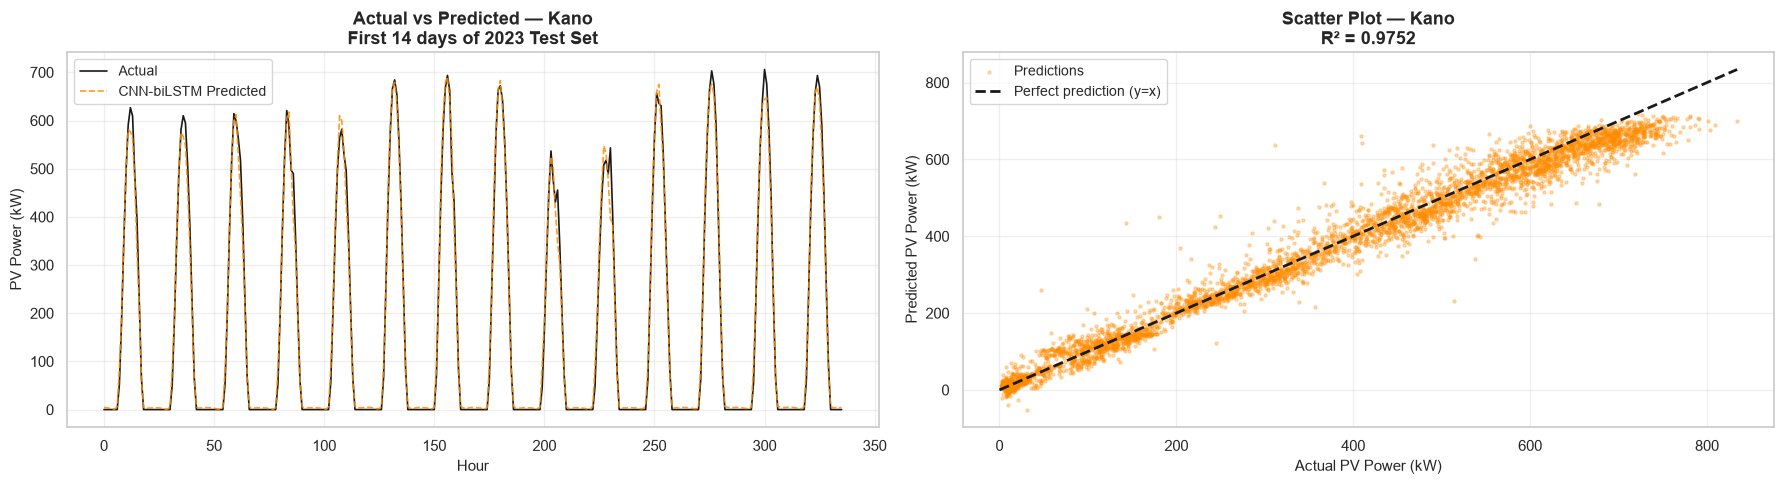

✅ Plot saved: C:/Users/Mahir/Desktop/Solar_Energy_Forecasting_Project\plots\Predictions_kano.png


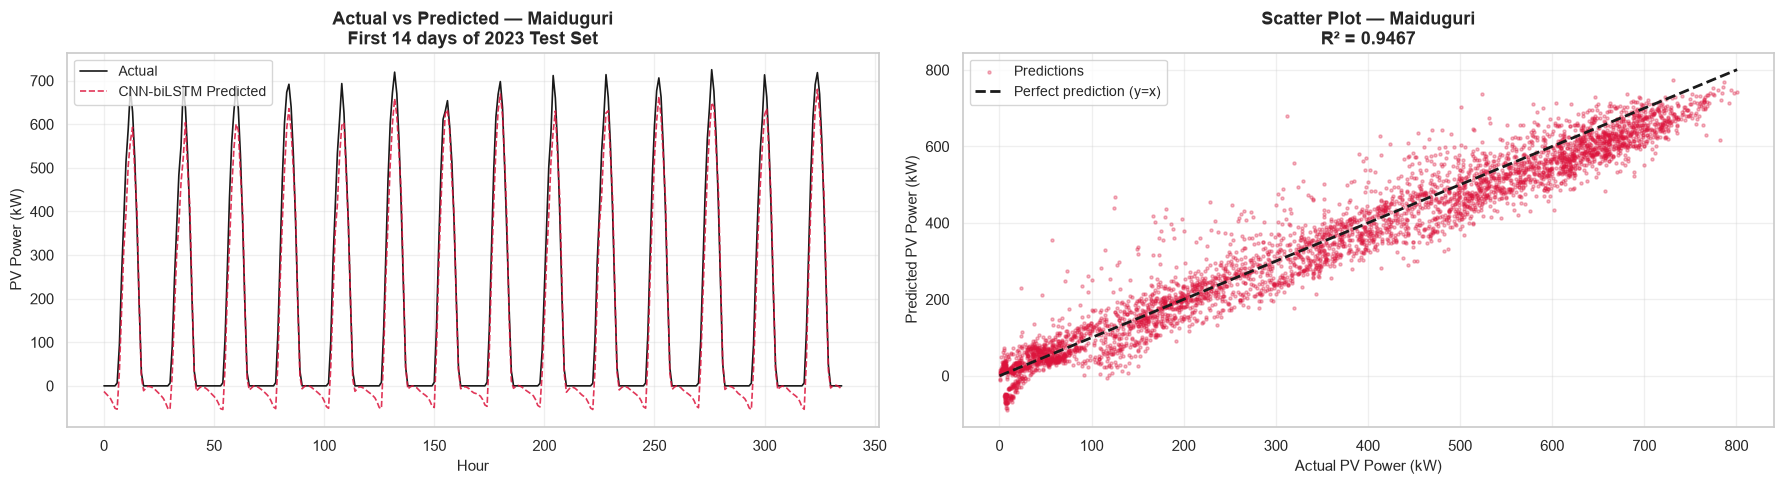

✅ Plot saved: C:/Users/Mahir/Desktop/Solar_Energy_Forecasting_Project\plots\Predictions_maiduguri.png


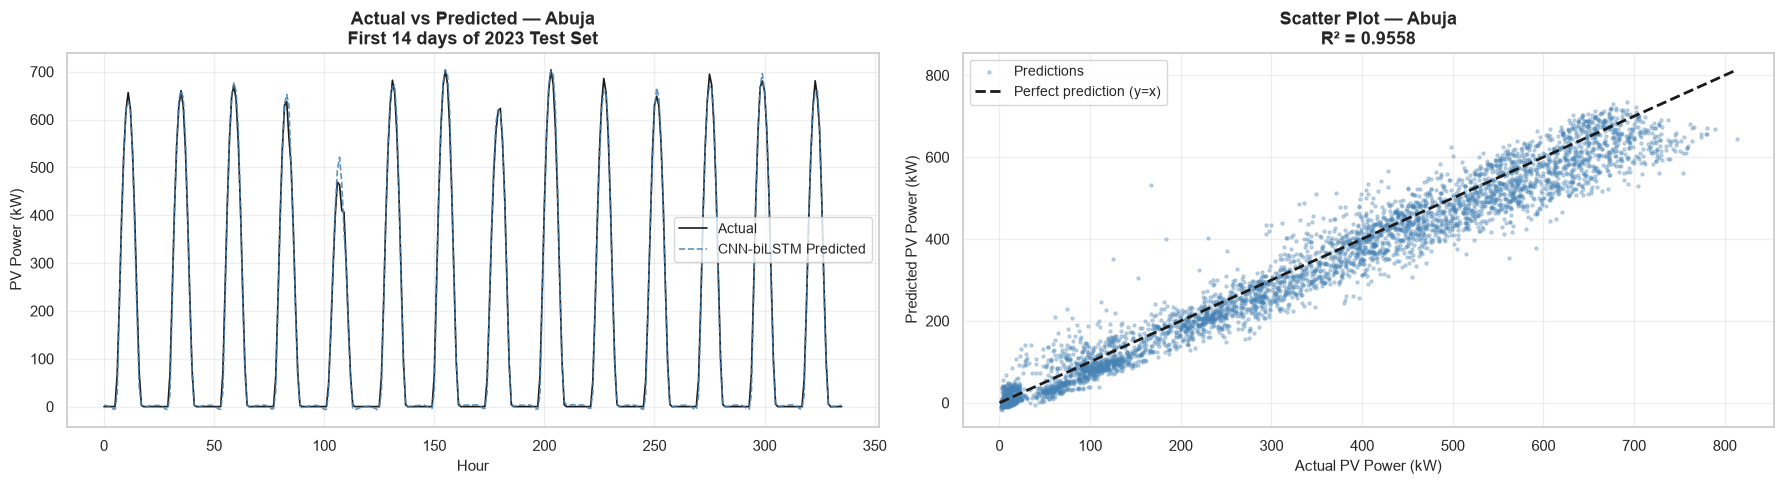

✅ Plot saved: C:/Users/Mahir/Desktop/Solar_Energy_Forecasting_Project\plots\Predictions_abuja.png


In [9]:
# ============================================================
# STAGE 4 - CELL 9: Plot Actual vs Predicted — All Cities
# ============================================================

def plot_predictions(y_true, y_pred, city_name,
                     color, n_days=14):
    """
    Plots actual vs predicted PV power for a sample period.
    Shows n_days of hourly data for visual assessment.
    Also creates a scatter plot for correlation assessment.
    """

    fig, axes = plt.subplots(1, 2, figsize=(18, 5))

    # ── Time Series Plot ──────────────────────────────────────
    # Show first n_days × 24 hours of test data
    n_hours = n_days * 24

    axes[0].plot(range(n_hours),
                 y_true[:n_hours],
                 color='black', linewidth=1.2,
                 label='Actual', alpha=0.9)
    axes[0].plot(range(n_hours),
                 y_pred[:n_hours],
                 color=color, linewidth=1.2,
                 linestyle='--',
                 label='CNN-biLSTM Predicted',
                 alpha=0.85)

    axes[0].set_title(f'Actual vs Predicted — {city_name}\n'
                       f'First {n_days} days of 2023 Test Set',
                       fontsize=13, fontweight='bold')
    axes[0].set_xlabel('Hour', fontsize=11)
    axes[0].set_ylabel('PV Power (kW)', fontsize=11)
    axes[0].legend(fontsize=10)

    # ── Scatter Plot ──────────────────────────────────────────
    # Daytime only
    mask = y_true > 0
    axes[1].scatter(y_true[mask], y_pred[mask],
                    alpha=0.3, s=5,
                    color=color, label='Predictions')

    # Perfect prediction line (y = x)
    max_val = max(y_true[mask].max(), y_pred[mask].max())
    axes[1].plot([0, max_val], [0, max_val],
                 'k--', linewidth=2,
                 label='Perfect prediction (y=x)')

    r2 = r2_score(y_true[mask], y_pred[mask])
    axes[1].set_title(f'Scatter Plot — {city_name}\n'
                       f'R² = {r2:.4f}',
                       fontsize=13, fontweight='bold')
    axes[1].set_xlabel('Actual PV Power (kW)', fontsize=11)
    axes[1].set_ylabel('Predicted PV Power (kW)', fontsize=11)
    axes[1].legend(fontsize=10)

    plt.tight_layout()

    save_path = os.path.join(
        PLOTS_DIR,
        f'Predictions_{city_name.lower()}.png')
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"✅ Plot saved: {save_path}")


# Plot for all three cities
plot_predictions(y_true_kw_kano,  y_pred_kw_kano,
                 'Kano',      'darkorange')
plot_predictions(y_true_kw_maid,  y_pred_kw_maid,
                 'Maiduguri', 'crimson')
plot_predictions(y_true_kw_abuja, y_pred_kw_abuja,
                 'Abuja',     'steelblue')

In [10]:
# ============================================================
# STAGE 4 - CELL 10: Save Predictions and Model Outputs
# ============================================================

# Save predictions for use in Stage 5 (XGBoost residuals)
# We save both the actual values and CNN-biLSTM predictions
# so XGBoost can learn to correct the residual errors

np.save(os.path.join(RESULTS_DIR, 'y_true_kano.npy'),
        y_true_kw_kano)
np.save(os.path.join(RESULTS_DIR, 'y_pred_cnn_kano.npy'),
        y_pred_kw_kano)

np.save(os.path.join(RESULTS_DIR, 'y_true_maid.npy'),
        y_true_kw_maid)
np.save(os.path.join(RESULTS_DIR, 'y_pred_cnn_maid.npy'),
        y_pred_kw_maid)

np.save(os.path.join(RESULTS_DIR, 'y_true_abuja.npy'),
        y_true_kw_abuja)
np.save(os.path.join(RESULTS_DIR, 'y_pred_cnn_abuja.npy'),
        y_pred_kw_abuja)

# Also save training predictions for XGBoost training
y_train_pred_kano  = model_kano.predict(
    X_train_kano, verbose=0).flatten()
y_train_pred_maid  = model_maid.predict(
    X_train_maid, verbose=0).flatten()
y_train_pred_abuja = model_abuja.predict(
    X_train_abuja, verbose=0).flatten()

np.save(os.path.join(RESULTS_DIR,
                      'y_train_pred_cnn_kano.npy'),
        y_train_pred_kano)
np.save(os.path.join(RESULTS_DIR,
                      'y_train_pred_cnn_maid.npy'),
        y_train_pred_maid)
np.save(os.path.join(RESULTS_DIR,
                      'y_train_pred_cnn_abuja.npy'),
        y_train_pred_abuja)

print("="*55)
print("ALL PREDICTIONS SAVED")
print("="*55)
print("\n✅ Test predictions (all 3 cities)")
print("✅ Train predictions (for XGBoost training)")
print("\nReady for Stage 5 — XGBoost Residual Correction")

ALL PREDICTIONS SAVED

✅ Test predictions (all 3 cities)
✅ Train predictions (for XGBoost training)

Ready for Stage 5 — XGBoost Residual Correction


In [11]:
# ============================================================
# STAGE 4 - CELL 11: Stage 4 Completion Summary
# ============================================================

print("="*60)
print("STAGE 4 COMPLETE — CNN-biLSTM MODEL TRAINING")
print("="*60)
print()
print("✅ CNN-biLSTM architecture built:")
print("   Input Layer   : (24 timesteps × 17 features)")
print("   CNN Block 1   : 64 filters, kernel=5, ReLU,")
print("                   BatchNorm, Dropout(0.10)")
print("   CNN Block 2   : 64 filters, kernel=5, ReLU,")
print("                   BatchNorm, Dropout(0.10)")
print("   BiLSTM Layer  : 64 units/direction (128 total),")
print("                   Dropout(0.10)")
print("   Output Layer  : Dense(1), linear activation")
print()
print("✅ Three models trained (one per city):")
print(f"   Kano epochs      : "
      f"{len(history_kano.history['loss'])}")
print(f"   Maiduguri epochs : "
      f"{len(history_maid.history['loss'])}")
print(f"   Abuja epochs     : "
      f"{len(history_abuja.history['loss'])}")
print()
print("✅ Performance on 2023 Test Set:")
print(f"   {'City':<12} {'RMSE':>8} {'MAE':>8} "
      f"{'R²':>10} {'MAPE':>8}")
print(f"   {'-'*48}")
for _, row in metrics_df.iterrows():
    print(f"   {row['city']:<12} "
          f"{row['RMSE']:>8.4f} "
          f"{row['MAE']:>8.4f} "
          f"{row['R2']:>10.6f} "
          f"{row['MAPE']:>7.2f}%")
print()
print("✅ Best models saved to models/ folder")
print("✅ Predictions saved for Stage 5")
print()
print("NEXT → Stage 5: XGBoost Residual Correction")
print("="*60)

STAGE 4 COMPLETE — CNN-biLSTM MODEL TRAINING

✅ CNN-biLSTM architecture built:
   Input Layer   : (24 timesteps × 17 features)
   CNN Block 1   : 64 filters, kernel=5, ReLU,
                   BatchNorm, Dropout(0.10)
   CNN Block 2   : 64 filters, kernel=5, ReLU,
                   BatchNorm, Dropout(0.10)
   BiLSTM Layer  : 64 units/direction (128 total),
                   Dropout(0.10)
   Output Layer  : Dense(1), linear activation

✅ Three models trained (one per city):
   Kano epochs      : 31
   Maiduguri epochs : 41
   Abuja epochs     : 19

✅ Performance on 2023 Test Set:
   City             RMSE      MAE         R²     MAPE
   ------------------------------------------------
   Kano          37.1633  25.9985   0.975220   18.79%
   Maiduguri     54.1675  41.4907   0.946654   46.29%
   Abuja         47.2580  35.6903   0.955765   31.08%

✅ Best models saved to models/ folder
✅ Predictions saved for Stage 5

NEXT → Stage 5: XGBoost Residual Correction
